In [52]:
##importing package

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.stats import ttest_ind
import statsmodels.formula.api as smf
from statsmodels.gam.api import GLMGam, BSplines
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from scipy.stats import chi2
from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test


In [37]:
#lets get this new dataset going
df = pd.read_csv("/Users/dustinh/Downloads/Q1data.csv")

df

,Time,Dead
0,1,1
1,1,1
2,1,1
3,1,1
4,2,1
5,2,1
6,2,1
7,2,1
8,2,1
9,2,1


          KM_estimate
timeline             
0.0           1.00000
1.0           0.87500
2.0           0.50000
3.0           0.37500
4.0           0.28125
5.0           0.21875
6.0           0.15625
7.0           0.12500
8.0           0.09375
11.0          0.06250
13.0          0.03125
15.0          0.00000


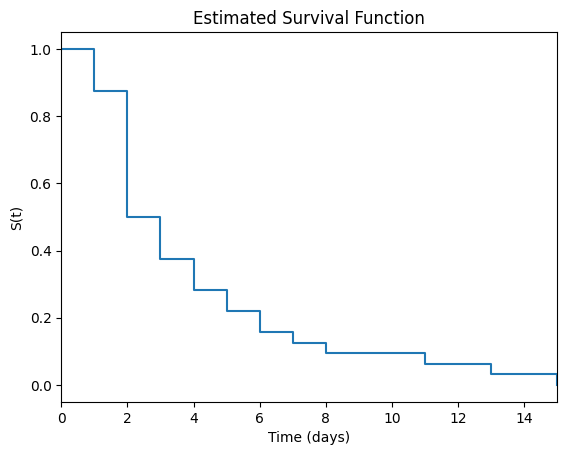

In [38]:
# If one row per time point: expand counts into one row per person (32 rows)
times = np.repeat(df["Time"], df["Dead"])
status = np.ones(len(times))   # 1 = event happened (no censoring)

kmf = KaplanMeierFitter()
kmf.fit(times, event_observed=status)
print(kmf.survival_function_)   # should match your S(t) column

kmf.plot_survival_function(ci_show=False, legend=False)
plt.xlabel("Time (days)")
plt.ylabel("S(t)")
plt.title("Estimated Survival Function")
plt.xlim(0, 15)
plt.savefig("survival_curve.png", dpi=300)
plt.show()

In [39]:
#now we need to calculate median, mean, percentile


print("Mean:  ", np.mean(times))
print("Median:", np.percentile(times, 50, method="inverted_cdf"))
print("25th:  ", np.percentile(times, 25, method="inverted_cdf"))
print("75th:  ", np.percentile(times, 75, method="inverted_cdf"))

Mean:   4.0
Median: 2
25th:   2
75th:   5


In [40]:
#importing the second data set 
df2 = pd.read_csv("/Users/dustinh/Downloads/Q2data.csv")
df2

,respdays,response
0,22,1
1,2,1
2,48,1
3,85,1
4,160,1
5,238,1
6,56,0
7,94,0
8,51,0
9,12,1


In [41]:
time, event = df2["respdays"], df2["response"] 

#there is a kaplanmeir class to bring in

kmf = KaplanMeierFitter()
kmf.fit(time, event_observed=event) 


tab = kmf.event_table
tab = tab[tab["observed"] > 0].copy()
r, d = tab["at_risk"], tab["observed"]
greenwood = (d / (r * (r - d))).cumsum()   # infinite at the last time (r = d)
S = kmf.survival_function_.loc[tab.index, "KM_estimate"]
z = 1.96


v = np.sqrt(greenwood) / np.abs(np.log(S))
ll_lo = S ** np.exp(z * v)
ll_hi = S ** np.exp(-z * v)


se = S * np.sqrt(greenwood)
lin_lo = S - z * se
lin_hi = S + z * se


out = pd.DataFrame({"S(t)": S, "loglog_lower": ll_lo, "loglog_upper": ll_hi,
                    "linear_lower": lin_lo, "linear_upper": lin_hi}).round(3)

print(out)

           S(t)  loglog_lower  loglog_upper  linear_lower  linear_upper
event_at                                                               
2.0       0.941         0.650         0.991         0.829         1.053
3.0       0.882         0.606         0.969         0.729         1.036
4.0       0.824         0.547         0.939         0.642         1.005
12.0      0.765         0.488         0.904         0.563         0.966
22.0      0.706         0.431         0.866         0.489         0.922
48.0      0.647         0.377         0.823         0.420         0.874
80.0      0.575         0.307         0.772         0.333         0.817
85.0      0.503         0.244         0.716         0.254         0.752
90.0      0.431         0.187         0.656         0.181         0.682
160.0     0.345         0.122         0.584         0.094         0.596
171.0     0.259         0.069         0.505         0.020         0.497
180.0     0.173         0.030         0.416        -0.038       

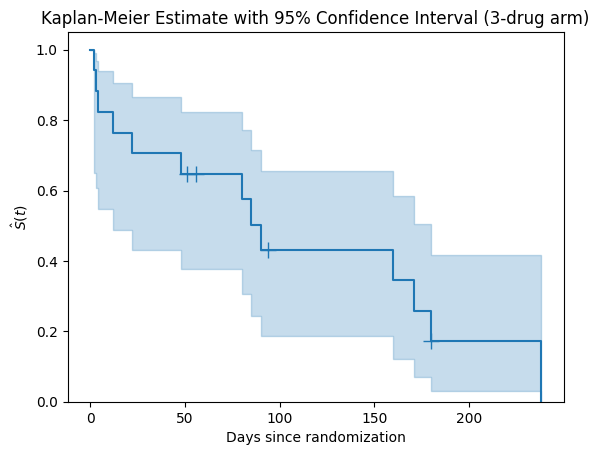

       KM_estimate_lower_0.95  KM_estimate_upper_0.95
0.0                     1.000                   1.000
2.0                     0.650                   0.991
3.0                     0.606                   0.969
4.0                     0.547                   0.939
12.0                    0.488                   0.904
22.0                    0.431                   0.866
48.0                    0.377                   0.823
51.0                    0.377                   0.823
56.0                    0.377                   0.823
80.0                    0.307                   0.772
85.0                    0.244                   0.716
90.0                    0.187                   0.656
94.0                    0.187                   0.656
160.0                   0.122                   0.584
171.0                   0.069                   0.505
180.0                   0.030                   0.416
238.0                   0.000                   0.000


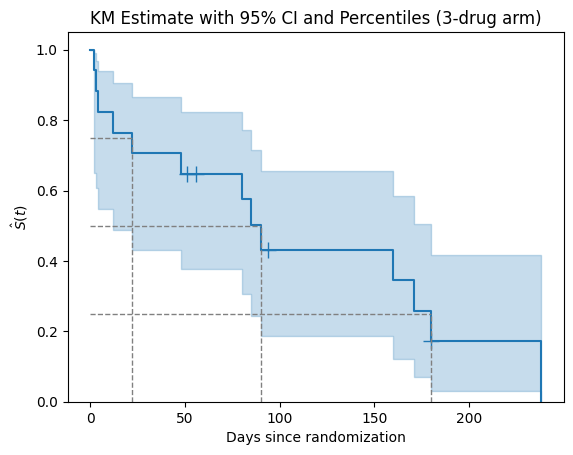

In [42]:
#ok now it's time to plot new data

ax = kmf.plot_survival_function(ci_show=True, show_censors=True, legend=False)
ax.set_xlabel("Days since randomization")
ax.set_ylabel(r"$\hat{S}(t)$")
ax.set_title("Kaplan-Meier Estimate with 95% Confidence Interval (3-drug arm)")
ax.set_ylim(0, 1.05)
plt.savefig("km_curve_q2c.png", dpi=300, bbox_inches="tight")
plt.show()

print(kmf.confidence_interval_.round(3))

#we need to add some lines at 25 and 75 percentile
ax = kmf.plot_survival_function(ci_show=True, show_censors=True, legend=False)

# percentile lines: across from the y-axis, then down to the x-axis
for level, t in [(0.75, 22), (0.50, 90), (0.25, 180)]:
    ax.hlines(level, 0, t, color="gray", linestyle="--", linewidth=1)
    ax.vlines(t, 0, level, color="gray", linestyle="--", linewidth=1)

ax.set_xlabel("Days since randomization")
ax.set_ylabel(r"$\hat{S}(t)$")
ax.set_title("KM Estimate with 95% CI and Percentiles (3-drug arm)")
ax.set_ylim(0, 1.05)
plt.savefig("km_percentiles_q2d.png", dpi=300, bbox_inches="tight")
plt.show()

In [43]:
#now we need to pull exact percetnages for the next question

for t in [22, 90, 180]:
    print(t, round(kmf.survival_function_at_times(t).iloc[0], 3))

22 0.706
90 0.431
180 0.173


In [44]:
#now we are using our next dataset

df3 = pd.read_stata("/Users/dustinh/Downloads/MIstudy.dta")

df3

,id,age,gender,hr,sysbp,diasbp,bmi,cvd,afib,shock,...,year,los,dstat,fuptime,fupstat,obese,overweight,obese_ovwt,dthtime,dthstat
0,1.0,83.0,0.0,89.0,152.0,78.0,25.540501,1.0,1.0,0.0,...,1.0,5.0,0.0,71.644699,0.0,0.0,1.0,1.0,71.644699,0.0
1,2.0,49.0,0.0,84.0,120.0,60.0,24.024000,1.0,0.0,0.0,...,1.0,5.0,0.0,71.447403,0.0,0.0,0.0,0.0,71.447403,0.0
2,3.0,70.0,1.0,83.0,147.0,88.0,22.142900,0.0,0.0,0.0,...,1.0,5.0,0.0,72.039497,0.0,0.0,0.0,0.0,72.039497,0.0
3,4.0,70.0,0.0,65.0,123.0,76.0,26.631901,1.0,0.0,0.0,...,1.0,10.0,0.0,9.769700,1.0,0.0,1.0,1.0,9.769700,1.0
4,5.0,70.0,0.0,63.0,135.0,85.0,24.412600,1.0,0.0,0.0,...,1.0,6.0,0.0,70.098701,0.0,0.0,0.0,0.0,70.098701,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496.0,76.0,1.0,68.0,112.0,88.0,27.964500,1.0,1.0,0.0,...,3.0,1.0,0.0,0.328900,1.0,0.0,1.0,1.0,0.328900,1.0
496,497.0,76.0,1.0,88.0,208.0,96.0,24.268600,1.0,0.0,0.0,...,3.0,3.0,0.0,21.776300,0.0,0.0,0.0,0.0,21.776300,0.0
497,498.0,57.0,1.0,123.0,120.0,74.0,42.135799,1.0,1.0,0.0,...,3.0,3.0,0.0,23.848700,0.0,1.0,0.0,1.0,23.848700,0.0
498,499.0,67.0,0.0,59.0,112.0,62.0,27.409100,1.0,0.0,0.0,...,3.0,1.0,0.0,17.500000,0.0,0.0,1.0,1.0,17.500000,0.0


In [45]:
#fittin the cox proportional model

print(df3[["dthtime", "dthstat", "obese_ovwt"]].head())
print(df3["dthstat"].value_counts())   # should be 0s and 1s

#Q3A: simple (unadjusted) Cox model with obese_ovwt as the only covariate
cox_a = CoxPHFitter()
cox_a.fit(df3[["dthtime", "dthstat", "obese_ovwt"]],
          duration_col="dthtime", event_col="dthstat")
cox_a.print_summary()

     dthtime  dthstat  obese_ovwt
0  71.644699      0.0         1.0
1  71.447403      0.0         0.0
2  72.039497      0.0         0.0
3   9.769700      1.0         1.0
4  70.098701      0.0         0.0
dthstat
0.0    285
1.0    215
Name: count, dtype: int64


<lifelines.CoxPHFitter: fitted with 500 total observations, 285 right-censored observations>
             duration col = 'dthtime'
                event col = 'dthstat'
      baseline estimation = breslow
   number of observations = 500
number of events observed = 215
   partial log-likelihood = -1207.79
         time fit was run = 2026-11-23 23:29:38 UTC

---
            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                   
obese_ovwt -0.86      0.42      0.14           -1.13           -0.59                0.32                0.55

            cmp to     z      p  -log2(p)
covariate                                
obese_ovwt    0.00 -6.24 <0.005     31.13
---
Concordance = 0.62
Partial AIC = 2417.58
log-likelihood ratio test = 39.06 on 1 df
-log2(p) of ll-ratio test = 31.18

In [ ]:
#lets get the test statistics

# LR statt
lr = cox_a.log_likelihood_ratio_test()
print("LR:   ", round(lr.test_statistic, 3), " p =", lr.p_value)


# Score stat
from lifelines.statistics import logrank_test
g1, g0 = df3[df3["obese_ovwt"] == 1], df3[df3["obese_ovwt"] == 0]
score = logrank_test(g1["dthtime"], g0["dthtime"],
event_observed_A=g1["dthstat"], event_observed_B=g0["dthstat"])
print("Score:", round(score.test_statistic, 3), " p =", score.p_value)

LR:    39.06  p = 4.1107001125697523e-10
Score: 41.43  p = 1.221603420474576e-10


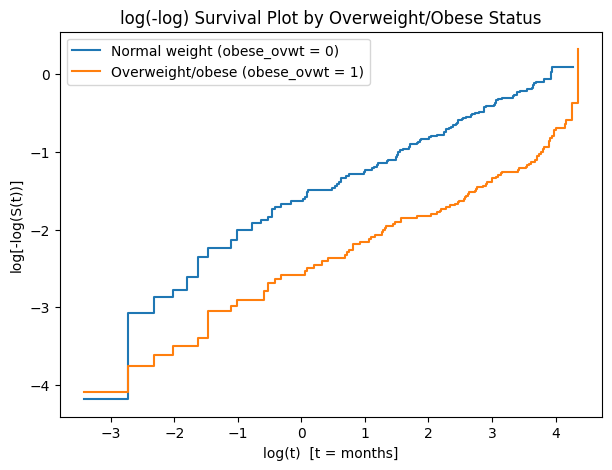

In [50]:
#time to make another plot

dat3 = df3[["dthtime", "dthstat", "obese_ovwt"]].dropna()

fig, ax = plt.subplots(figsize=(7, 5))
for g, label in [(0, "Normal weight (obese_ovwt = 0)"),
                 (1, "Overweight/obese (obese_ovwt = 1)")]:
    sub = dat3[dat3["obese_ovwt"] == g]
    km = KaplanMeierFitter().fit(sub["dthtime"], event_observed=sub["dthstat"])
    s = km.survival_function_["KM_estimate"]
    s = s[(s > 0) & (s < 1) & (s.index > 0)]   # log(-log S) and log(t) need 0 < S < 1, t > 0
    ax.step(np.log(s.index), np.log(-np.log(s)), where="post", label=label)

ax.set_xlabel("log(t)  [t = months]")
ax.set_ylabel("log[-log(S(t))]")
ax.set_title("log(-log) Survival Plot by Overweight/Obese Status")
ax.legend()
plt.savefig("loglog_q3b.png", dpi=300, bbox_inches="tight")
plt.show()

In [53]:
#plot looks good ,let's evaluate the values


# same data and model as Part A
dat3 = df3[["dthtime", "dthstat", "obese_ovwt"]].dropna()
cox_a = CoxPHFitter()
cox_a.fit(dat3, duration_col="dthtime", event_col="dthstat")

# Part B(ii): weighted (scaled) Schoenfeld residual test
ph = proportional_hazard_test(cox_a, dat3, time_transform="rank")
ph.print_summary()

<lifelines.StatisticalResult: proportional_hazard_test>
    time_transform = rank
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 500 total observations, 285 right-censored observations>
         test_name = proportional_hazard_test

---
            test_statistic    p  -log2(p)
obese_ovwt            1.04 0.31      1.70

In [54]:
#ok now we are getting more complex with our models

cols = ["dthtime", "dthstat", "obese_ovwt", "age", "gender", "sysbp", "mitype"]
dat3c = df3[cols].dropna()

cox_c = CoxPHFitter()
cox_c.fit(dat3c, duration_col="dthtime", event_col="dthstat")
cox_c.print_summary(decimals=3)

<lifelines.CoxPHFitter: fitted with 500 total observations, 285 right-censored observations>
             duration col = 'dthtime'
                event col = 'dthstat'
      baseline estimation = breslow
   number of observations = 500
number of events observed = 215
   partial log-likelihood = -1147.814
         time fit was run = 2026-11-24 00:09:31 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
obese_ovwt -0.447     0.639     0.146          -0.734          -0.160               0.480               0.852
age         0.060     1.061     0.006           0.047           0.072               1.048               1.075
gender     -0.120     0.887     0.142          -0.398           0.159               0.672               1.172
sysbp      -0.004     0.996     0.002          -0.008           0.001               0.992               1.001
mitype     -0.333     0.717     0.172          -0.670           0.004               0.512               1.004

            cmp to      z       p  -log2(p)
covariate                                  
obese_ovwt   0.000 -3.054   0.002     8.791
age          0.000  9.360 <0.0005    66.770
gender       0.000 -0.842   0.400     1.323
sysbp        0.000 -1.618   0.106     3.242
mitype       0.000 -1.937   0.053     4.245
---
Concordance = 0.744
Partial AIC = 2305.627
log-likelihood ratio test = 159.014 on 5 df
-log2(p) of ll-ratio test = 105.618

In [ ]:
print("Unadjusted (Part A):")
print(cox_a.summary.loc["obese_ovwt", ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3))

Unadjusted (Part A):
exp(coef)              0.423
exp(coef) lower 95%    0.323
exp(coef) upper 95%    0.554
p                      0.000
Name: obese_ovwt, dtype: float64


In [57]:
print("\nAdjusted (Part C):")
print(cox_c.summary.loc["obese_ovwt", ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3))

print("\nMean age by overweight/obese status:")
print(dat3c.groupby("obese_ovwt")["age"].mean().round(1))


Adjusted (Part C):
exp(coef)              0.639
exp(coef) lower 95%    0.480
exp(coef) upper 95%    0.852
p                      0.002
Name: obese_ovwt, dtype: float64

Mean age by overweight/obese status:
obese_ovwt
0.0    75.500000
1.0    66.099998
Name: age, dtype: float32
